<a href="https://colab.research.google.com/github/AndresMontesDeOca/vision_computadora_II/blob/VpC2_2026/CS_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from IPython.display import Audio, display, HTML

sr = 44100
signal = np.full(sr, 1e-6, dtype=np.float32)

# Renderiza el audio y fuerza loop="loop" en el elemento HTML generado
display(Audio(signal, rate=sr, autoplay=True))
display(HTML("""
<script>
  const audios = document.querySelectorAll('audio');
  audios.forEach(a => { a.loop = true; a.play().catch(() => {}); });
</script>
"""))

# **Clasificación y Detección de Objetos en Counter-Strike**

Este notebook contiene el pipeline completo para descargar un dataset de Counter-Strike desde Roboflow, realizar análisis exploratorio de datos (EDA), entrenar un modelo YOLOv11 de Ultralytics, evaluar las métricas de rendimiento y realizar inferencias/predicciones visuales utilizando Google Drive como almacenamiento persistente.

## **1. Configuración del Entorno e Importación de Librerías**

En esta sección instalamos las dependencias requeridas, montamos Google Drive para persistencia de datos e importamos los módulos necesarios.

In [ ]:
# Instalar librerías necesarias si no están presentes
!pip install roboflow ultralytics

import os
import yaml
import json
import random
import cv2
import glob
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata
from google.colab import drive
from roboflow import Roboflow
from ultralytics import YOLO

# Montar Google Drive al inicio de la sesión
drive.mount('/content/drive')

## **2. Descarga y Verificación del Dataset**

Utilizamos la API de Roboflow para descargar la versión adaptada a YOLOv11 de nuestro dataset de Counter-Strike de manera automatizada.

In [38]:
# Ruta esperada del dataset
dataset_path = '/content/Counter-Strike-1'

# Verificar si el dataset ya existe en el entorno
if not os.path.exists(dataset_path):
    print("El dataset no fue detectado. Iniciando descarga desde Roboflow...")
    api_key = userdata.get("ROBOFLOW_API_KEY")
    rf = Roboflow(api_key=api_key)

    # Descarga del dataset en formato YOLOv11
    project = rf.workspace("counter-strike-uovxc").project("counter-strike-h9y80")
    version = project.version(1)
    dataset = version.download("yolov11")
else:
    print(f"El dataset ya existe en '{dataset_path}'. Se omitió la descarga para optimizar tiempo.")

El dataset ya existe en '/content/Counter-Strike-1'. Se omitió la descarga para optimizar tiempo.


## **3. Análisis Exploratorio de Datos (EDA)**

Definimos funciones de visualización para inspeccionar nuestras imágenes de entrenamiento, analizar las distribuciones de clases y resoluciones para asegurar un entrenamiento estable.

Estructura y clases del dataset:
{
    "train": "../train/images",
    "val": "../valid/images",
    "test": "../test/images",
    "nc": 2,
    "names": [
        "ct",
        "t"
    ],
    "roboflow": {
        "workspace": "counter-strike-uovxc",
        "project": "counter-strike-h9y80",
        "version": 1,
        "license": "CC BY 4.0",
        "url": "https://universe.roboflow.com/counter-strike-uovxc/counter-strike-h9y80/dataset/1"
    }
}


Carpeta 'train': 2577 imágenes encontradas en /content/Counter-Strike-1/train/images
Carpeta 'val': 736 imágenes encontradas en /content/Counter-Strike-1/valid/images
Carpeta 'test': 368 imágenes encontradas en /content/Counter-Strike-1/test/images




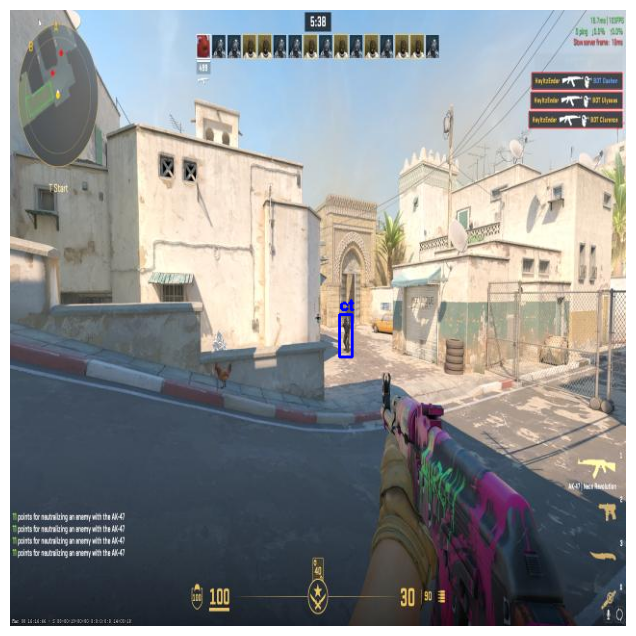

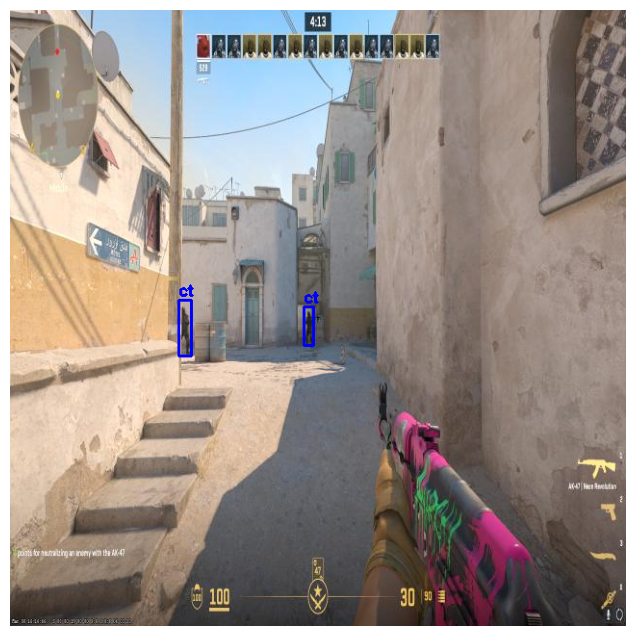

In [39]:
# Cargar y mostrar la configuración de clases y rutas
data_yaml_path = '/content/Counter-Strike-1/data.yaml'
with open(data_yaml_path, 'r') as file:
    dataset_info = yaml.safe_load(file)

print("Estructura y clases del dataset:")
print(json.dumps(dataset_info, indent=4))
print("\n" + "="*40 + "\n")

# --- Conteo de Imágenes por Carpeta ---
dataset_root = '/content/Counter-Strike-1'
for split in ['train', 'val', 'test']:
    yaml_key = split
    if split == 'val' and 'val' not in dataset_info and 'valid' in dataset_info:
        yaml_key = 'valid'

    if yaml_key in dataset_info:
        split_path = dataset_info[yaml_key].lstrip('./').replace('../', '')
        full_split_path = os.path.abspath(os.path.join(dataset_root, split_path))

        image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.JPG', '*.JPEG', '*.PNG')
        images_found = []
        for ext in image_extensions:
            images_found.extend(glob.glob(os.path.join(full_split_path, ext)))

        print(f"Carpeta '{split}': {len(images_found)} imágenes encontradas en {full_split_path}")
    else:
        print(f"No se encontró la definición de '{split}' o '{yaml_key}' en data.yaml")
print("\n" + "="*40 + "\n")

# Definición de parámetros principales para el EDA
images_dir = '/content/Counter-Strike-1/train/images'
labels_dir = '/content/Counter-Strike-1/train/labels'
class_names = dataset_info.get('names', ['ct', 't'])

# Función para graficar muestras YOLO
def plot_yolo_sample(img_path, lbl_path, class_names):
    if not os.path.exists(img_path):
        return
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape
    colors = [(0, 0, 255), (255, 0, 0)]  # Azul para CT, Rojo para Terroristas

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    cls_id = int(parts[0])
                    x_center, y_center, bbox_w, bbox_h = map(float, parts[1:])
                    x1 = int((x_center - bbox_w / 2) * w)
                    y1 = int((y_center - bbox_h / 2) * h)
                    x2 = int((x_center + bbox_w / 2) * w)
                    y2 = int((y_center + bbox_h / 2) * h)
                    color = colors[cls_id % len(colors)]
                    cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
                    label = class_names[cls_id]
                    cv2.putText(image, label, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    plt.axis('off')
    plt.show()

def plot_random_samples(images_dir, labels_dir, class_names, num_samples=3):
    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    selected_images = random.sample(all_images, min(len(all_images), num_samples))
    for img_name in selected_images:
        lbl_name = img_name.rsplit('.', 1)[0] + '.txt'
        plot_yolo_sample(os.path.join(images_dir, img_name), os.path.join(labels_dir, lbl_name), class_names)

# Mostrar muestras aleatorias etiquetadas
plot_random_samples(images_dir, labels_dir, class_names, num_samples=2)

,Train,Valid,Test
Counter-Terrorist (ct),1778,522,246
Terrorist (t),1664,476,233


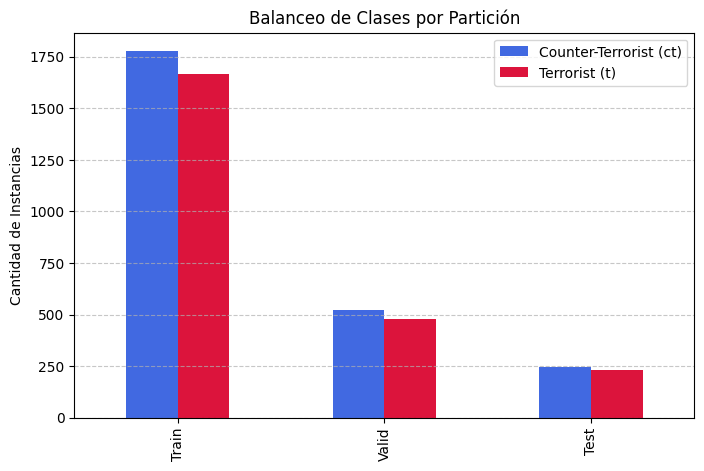

In [40]:
# Análisis del balance de clases en cada partición
particiones = {
    'Train': '/content/Counter-Strike-1/train/labels',
    'Valid': '/content/Counter-Strike-1/valid/labels',
    'Test': '/content/Counter-Strike-1/test/labels'
}

resultados = {}
for nombre, ruta in particiones.items():
    counts = {0: 0, 1: 0}
    if os.path.exists(ruta):
        for file in os.listdir(ruta):
            if file.endswith('.txt'):
                with open(os.path.join(ruta, file), 'r') as f:
                    for line in f:
                        parts = line.strip().split()
                        if parts:
                            cls_id = int(parts[0])
                            if cls_id in counts:
                                counts[cls_id] += 1
    resultados[nombre] = counts

df_balance = pd.DataFrame(resultados).rename(index={0: 'Counter-Terrorist (ct)', 1: 'Terrorist (t)'})
display(df_balance)

# Graficar Balance de Clases
fig, ax = plt.subplots(figsize=(8, 5))
df_balance.T.plot(kind='bar', ax=ax, color=['royalblue', 'crimson'])
plt.title('Balanceo de Clases por Partición')
plt.ylabel('Cantidad de Instancias')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## **4. Entrenamiento del Modelo (YOLOv11)**

Inicializamos y entrenamos el detector con arquitectura YOLOv11 utilizando los hiperparámetros óptimos seleccionados.

In [41]:
# Configuración del flujo de entrenamiento
entrenar = False  # True para entrenar un modelo nuevo, False para saltarlo y cargar pesos previos

# Versión de YOLOv11 a utilizar. Opciones disponibles:
# - "yolo11n.pt" (Nano: extremadamente rápido, ideal para CPU/móviles)
# - "yolo11s.pt" (Small: balance velocidad/precisión)
# - "yolo11m.pt" (Medium: para mayor precisión en detecciones complejas)
# - "yolo11l.pt" (Large: mayor precisión, requiere más memoria GPU)
# - "yolo11x.pt" (X-Large: máxima precisión, entrenamiento más lento)
modelo_version = "yolo11m.pt"

# Hiperparámetros generales de entrenamiento
epocas = 200
tamanio_batch = 8
paciencia = 15  # Número de épocas a esperar sin mejora antes de detener el entrenamiento (Early Stopping)

print(f"Configuración cargada:\n- Entrenar: {entrenar}\n- Modelo base: {modelo_version}\n- Épocas: {epocas}\n- Batch size: {tamanio_batch}\n- Paciencia (Early Stopping): {paciencia}")

Configuración cargada:
- Entrenar: False
- Modelo base: yolo11m.pt
- Épocas: 200
- Batch size: 8
- Paciencia (Early Stopping): 15


In [42]:
import os
import shutil

if entrenar:
    print(f"Iniciando entrenamiento del modelo seleccionado: {modelo_version}...")
    # Inicializar la arquitectura elegida dinámicamente
    model = YOLO(modelo_version)

    # Comenzar entrenamiento con los parámetros seleccionados por el usuario
    results = model.train(
        data="/content/Counter-Strike-1/data.yaml",
        epochs=epocas,
        patience=paciencia,
        imgsz=640,
        batch=tamanio_batch,
        project="runs",
        name="cs_v2",
        exist_ok=True
    )

    # --- EXPORTACIÓN AUTOMÁTICA E INMEDIATA A GOOGLE DRIVE TRAS ENTRENAR ---
    print("\n--- Iniciando exportación automática de resultados a Google Drive ---")
    modelo_id = modelo_version.replace(".pt", "") if 'modelo_version' in globals() else "yolo11m"

    # Rutas locales origen
    local_results_csv = "runs/detect/runs/cs_v2/results.csv"
    local_best_weights = "runs/detect/runs/cs_v2/weights/best.pt"

    # Rutas destino en Google Drive
    drive_dest_dir = '/content/drive/MyDrive/CounterStrike_YOLO_Metrics'
    drive_csv_path = os.path.join(drive_dest_dir, f"{modelo_id}_training_metrics_backup.csv")
    drive_weights_path = os.path.join(drive_dest_dir, "weights", f"{modelo_id}_best.pt")

    os.makedirs(os.path.join(drive_dest_dir, "weights"), exist_ok=True)

    # Exportar métricas CSV
    if os.path.exists(local_results_csv):
        try:
            shutil.copy(local_results_csv, drive_csv_path)
            print(f"[OK] Métricas exportadas a Drive: {drive_csv_path}")
        except Exception as e:
            print(f"[ALERTA] Error al exportar CSV de métricas: {e}")

    # Exportar pesos optimizados
    if os.path.exists(local_best_weights):
        try:
            shutil.copy(local_best_weights, drive_weights_path)
            print(f"[OK] Pesos optimizados exportados a Drive: {drive_weights_path}")
        except Exception as e:
            print(f"[ALERTA] Error al exportar pesos: {e}")
else:
    print("\n[INFO] 'entrenar' está desactivado. Se omite el entrenamiento de esta sesión.")
    print("Los pesos y métricas se restaurarán o leerán directamente desde Google Drive en la sección 5.")


[INFO] 'entrenar' está desactivado. Se omite el entrenamiento de esta sesión.
Los pesos y métricas se restaurarán o leerán directamente desde Google Drive en la sección 5.


In [43]:
# Cargo los pesos entrenados anterioremente

import os
import shutil
import pandas as pd

# Obtener el nombre base del modelo limpio
modelo_id = modelo_version.replace(".pt", "") if 'modelo_version' in globals() else "yolo11m"

# Directorios locales de destino de la restauración
save_dir = "runs/detect/runs/cs_v2"
local_weights_path = os.path.join(save_dir, "weights", "best.pt")
local_csv_backup_path = os.path.join(save_dir, f"{modelo_id}_training_metrics_backup.csv")
local_target_weights_path = os.path.join(save_dir, "weights", f"{modelo_id}_best.pt")

# Directorios y nombres de archivos en Drive (Única Fuente de Verdad)
drive_dest_dir = '/content/drive/MyDrive/CounterStrike_YOLO_Metrics'
drive_csv_path = os.path.join(drive_dest_dir, f"{modelo_id}_training_metrics_backup.csv")
drive_weights_path = os.path.join(drive_dest_dir, "weights", f"{modelo_id}_best.pt")

os.makedirs(save_dir, exist_ok=True)

print(f"[INFO] CARGA EXCLUSIVA: Descargando métricas y pesos directamente desde Google Drive para '{modelo_id}'...")

# 1. Cargar obligatoriamente métricas CSV de Drive
if os.path.exists(drive_csv_path):
    try:
        shutil.copy(drive_csv_path, local_csv_backup_path)
        print(f"[OK] Métricas de '{modelo_id}' cargadas exitosamente desde Drive al entorno local.")
    except Exception as e:
        print(f"[ERROR] No se pudieron copiar las métricas desde Drive: {e}")
else:
    print(f"[ALERTA] No se encontró el archivo de métricas en Drive: {drive_csv_path}")

# 2. Cargar obligatoriamente pesos optimizados de Drive
if os.path.exists(drive_weights_path):
    try:
        os.makedirs(os.path.dirname(local_weights_path), exist_ok=True)
        shutil.copy(drive_weights_path, local_target_weights_path)
        shutil.copy(drive_weights_path, local_weights_path)
        print(f"[OK] Pesos '{modelo_id}_best.pt' descargados exitosamente desde Drive al entorno local.")
    except Exception as e:
        print(f"[ERROR] No se pudieron copiar los pesos desde Drive: {e}")
else:
    print(f"[ALERTA] No se encontraron los pesos en Drive: {drive_weights_path}")

# 3. Mostrar vista previa de métricas cargadas para verificar el dataframe 'df'
if os.path.exists(local_csv_backup_path):
    df = pd.read_csv(local_csv_backup_path)
    display(df.head(5))
else:
    df = None
    print("[INFO] No hay métricas cargadas en memoria.")

[INFO] CARGA EXCLUSIVA: Descargando métricas y pesos directamente desde Google Drive para 'yolo11m'...
[OK] Métricas de 'yolo11m' cargadas exitosamente desde Drive al entorno local.
[OK] Pesos 'yolo11m_best.pt' descargados exitosamente desde Drive al entorno local.


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,48.8542,1.88364,1.94652,1.22727,0.00443,0.30902,0.00147,0.00063,2.61069,117.84600,1.96842,0.000554,0.000554,0.000554
1,2,95.9069,1.93992,1.51229,1.32917,0.71194,0.58354,0.63634,0.26551,1.94586,1.77707,1.42629,0.001104,0.001104,0.001104
2,3,142.8800,1.91586,1.43367,1.32363,0.81835,0.65162,0.73988,0.35810,1.69368,1.67078,1.31718,0.001649,0.001649,0.001649
3,4,189.7580,1.85989,1.37350,1.30252,0.73555,0.63320,0.69876,0.32148,1.75886,1.78566,1.31364,0.001642,0.001642,0.001642
4,5,236.3370,1.80937,1.27275,1.25297,0.81188,0.69660,0.78025,0.36818,1.75503,1.36975,1.32846,0.001634,0.001634,0.001634


## **7. Inferencia y Predicciones en Nuevas Muestras**

Esta sección carga los pesos optimizados del entrenamiento (`best.pt`) y realiza una prueba de predicción visual sobre una imagen aleatoria.

[INFO] Cargando exclusivamente pesos de inferencia desde Google Drive para yolo11m...
[OK] Pesos cargados exitosamente: /content/drive/MyDrive/CounterStrike_YOLO_Metrics/weights/yolo11m_best.pt
Results saved to /content/runs/detect/runs/cs_v2_pred
Results saved to /content/runs/detect/runs/cs_v2_pred
Results saved to /content/runs/detect/runs/cs_v2_pred
Results saved to /content/runs/detect/runs/cs_v2_pred
Results saved to /content/runs/detect/runs/cs_v2_pred


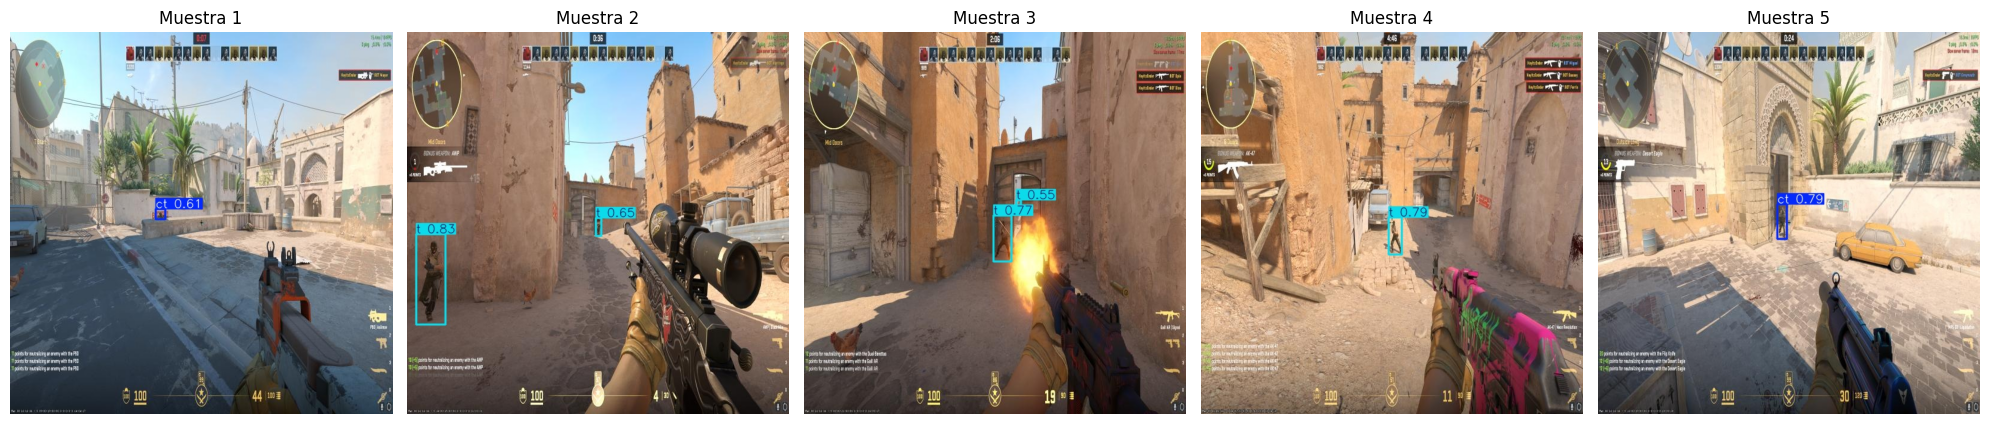

In [47]:
# Prediccion de 5 imagenes random de test

import os
import random
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Selección de 5 imágenes al azar
train_images_dir = "/content/Counter-Strike-1/test/images"
if os.path.exists(train_images_dir):
    all_train_images = [f for f in os.listdir(train_images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    num_imagenes_mostrar = min(len(all_train_images), 5)
    selected_images = random.sample(all_train_images, num_imagenes_mostrar)
else:
    raise FileNotFoundError("Directorio de entrenamiento no encontrado.")

# 2. Cargar directamente los pesos del modelo seleccionado desde Google Drive
modelo_id = modelo_version.replace(".pt", "") if 'modelo_version' in globals() else "yolo11m"
drive_weights_path = f"/content/drive/MyDrive/CounterStrike_YOLO_Metrics/weights/{modelo_id}_best.pt"

print(f"[INFO] Cargando exclusivamente pesos de inferencia desde Google Drive para {modelo_id}...")
if os.path.exists(drive_weights_path):
    print(f"[OK] Pesos cargados exitosamente: {drive_weights_path}")
    inference_model = YOLO(drive_weights_path)
else:
    raise FileNotFoundError(f"[ALERTA] No se encontraron los pesos optimizados en la ruta de Drive: {drive_weights_path}")

# 3. Realizar predicciones y mostrar las 5 imágenes en una cuadrícula
fig, axes = plt.subplots(1, num_imagenes_mostrar, figsize=(20, 5))
if num_imagenes_mostrar == 1:
    axes = [axes]

for idx, img_name in enumerate(selected_images):
    img_path = os.path.join(train_images_dir, img_name)

    # Ejecutar predicción sin guardar logs redundantes
    preds = inference_model.predict(source=img_path, imgsz=640, conf=0.4, save=True, project="runs", name="cs_v2_pred", exist_ok=True, verbose=False)

    # Ruta del archivo guardado por Ultralytics
    result_image_path = os.path.join(preds[0].save_dir, os.path.basename(preds[0].path))

    if os.path.exists(result_image_path):
        img = cv2.imread(result_image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(img)
        axes[idx].set_title(f"Muestra {idx+1}")
        axes[idx].axis("off")
    else:
        axes[idx].text(0.5, 0.5, "Error al cargar imagen", ha='center', va='center')
        axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [48]:
# Performance en test

import os
import json
import shutil
from ultralytics import YOLO

# 1. Definir rutas de los pesos específicos en Google Drive
modelo_id = modelo_version.replace(".pt", "") if 'modelo_version' in globals() else "yolo11m"
drive_dest_dir = '/content/drive/MyDrive/CounterStrike_YOLO_Metrics'
drive_weights_path = f"{drive_dest_dir}/weights/{modelo_id}_best.pt"

# Forzar la carga exclusiva desde Google Drive
if os.path.exists(drive_weights_path):
    print(f"[INFO] Cargando exclusivamente pesos desde Google Drive para evaluación: {drive_weights_path}")
    model_eval = YOLO(drive_weights_path)
else:
    raise FileNotFoundError(f"[ALERTA] No se encontraron los pesos en Google Drive: {drive_weights_path}")

# 2. Ejecutar la validación en el conjunto de prueba (split='test')
print(f"\n--- Iniciando Evaluación en el Conjunto de Test para {modelo_id} ---")
metrics_test = model_eval.val(
    data="/content/Counter-Strike-1/data.yaml",
    split="test",
    imgsz=640,
    project="runs",
    name="cs_v2_test_evaluation",
    exist_ok=True
)

# 3. Extraer métricas de interés
test_results = {
    "modelo_id": modelo_id,
    "mAP50": float(metrics_test.results_dict['metrics/mAP50(B)']),
    "mAP50-95": float(metrics_test.results_dict['metrics/mAP50-95(B)']),
    "precision": float(metrics_test.results_dict['metrics/precision(B)']),
    "recall": float(metrics_test.results_dict['metrics/recall(B)']),
    "ct_mAP50": float(metrics_test.results_dict.get('metrics/mAP50(B)', 0.0)) if len(metrics_test.curves_results) == 0 else float(metrics_test.box.class_result(0)[2]),
    "t_mAP50": float(metrics_test.results_dict.get('metrics/mAP50(B)', 0.0)) if len(metrics_test.curves_results) == 0 else float(metrics_test.box.class_result(1)[2])
}

# 4. Guardar y respaldar las métricas JSON directamente en Google Drive
json_file_name = f"{modelo_id}_test_metrics_backup.json"
local_json_path = os.path.join("runs/detect/runs/cs_v2", json_file_name)
drive_json_path = os.path.join(drive_dest_dir, json_file_name)

# Guardar copia local y copiar directamente a Drive de manera obligatoria
os.makedirs(os.path.dirname(local_json_path), exist_ok=True)
with open(local_json_path, 'w') as f:
    json.dump(test_results, f, indent=4)

try:
    os.makedirs(drive_dest_dir, exist_ok=True)
    shutil.copy(local_json_path, drive_json_path)
    print(f"\n[OK] Métricas de test de '{modelo_id}' exportadas directamente a Drive con éxito: {drive_json_path}")
except Exception as e:
    print(f"\n[ALERTA] Error al escribir el archivo de métricas de test en Google Drive: {e}")

# 5. Mostrar resultados por pantalla
print("\n" + "="*50)
print("     MÉTRICAS FINALES EN EL CONJUNTO DE TEST")
print("="*50)
print(f"mAP50 (Box):      {test_results['mAP50']:.4f}")
print(f"mAP50-95 (Box):   {test_results['mAP50-95']:.4f}")
print(f"Precisión (P):    {test_results['precision']:.4f}")
print(f"Exhaustividad (R): {test_results['recall']:.4f}")
print("="*50)

[INFO] Cargando exclusivamente pesos desde Google Drive para evaluación: /content/drive/MyDrive/CounterStrike_YOLO_Metrics/weights/yolo11m_best.pt

--- Iniciando Evaluación en el Conjunto de Test para yolo11m ---
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11m summary (fused): 125 layers, 20,031,574 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2150.8±477.4 MB/s, size: 68.5 KB)
val: Scanning /content/Counter-Strike-1/test/labels.cache... 368 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 368/368 85.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.9it/s 5.9s
                   all        368        479      0.942      0.943      0.954      0.514
                    ct        219        246      0.948      0.951      0.972      0.527
                     t        202        233      0.936      0.936      0.937      0.502

## **9. YOLOv11 Medium: Data Augmentation & Optimization**

Esta sección está reservada para que realices experimentos con técnicas de *Data Augmentation* personalizadas (ajustes de brillo, contraste, mosaicos o desenfoques) y optimización de hiperparámetros aplicados al modelo **YOLOv11 Medium**, con el fin de superar el rendimiento actual en la detección de Terroristas (t) y Anti-Terroristas (ct) en Counter-Strike.

Mounted at /content/drive
Buscando archivos de métricas...
 -> Cargando yolo11n desde: /content/drive/MyDrive/CounterStrike_YOLO_Metrics/yolo11n_training_metrics_backup.csv
 -> Cargando yolo11s desde: /content/drive/MyDrive/CounterStrike_YOLO_Metrics/yolo11s_training_metrics_backup.csv
 -> Cargando yolo11m desde: /content/drive/MyDrive/CounterStrike_YOLO_Metrics/yolo11m_training_metrics_backup.csv
 -> Cargando yolo11l desde: /content/drive/MyDrive/CounterStrike_YOLO_Metrics/yolo11l_training_metrics_backup.csv
 -> Cargando yolo11x desde: /content/drive/MyDrive/CounterStrike_YOLO_Metrics/yolo11x_training_metrics_backup.csv


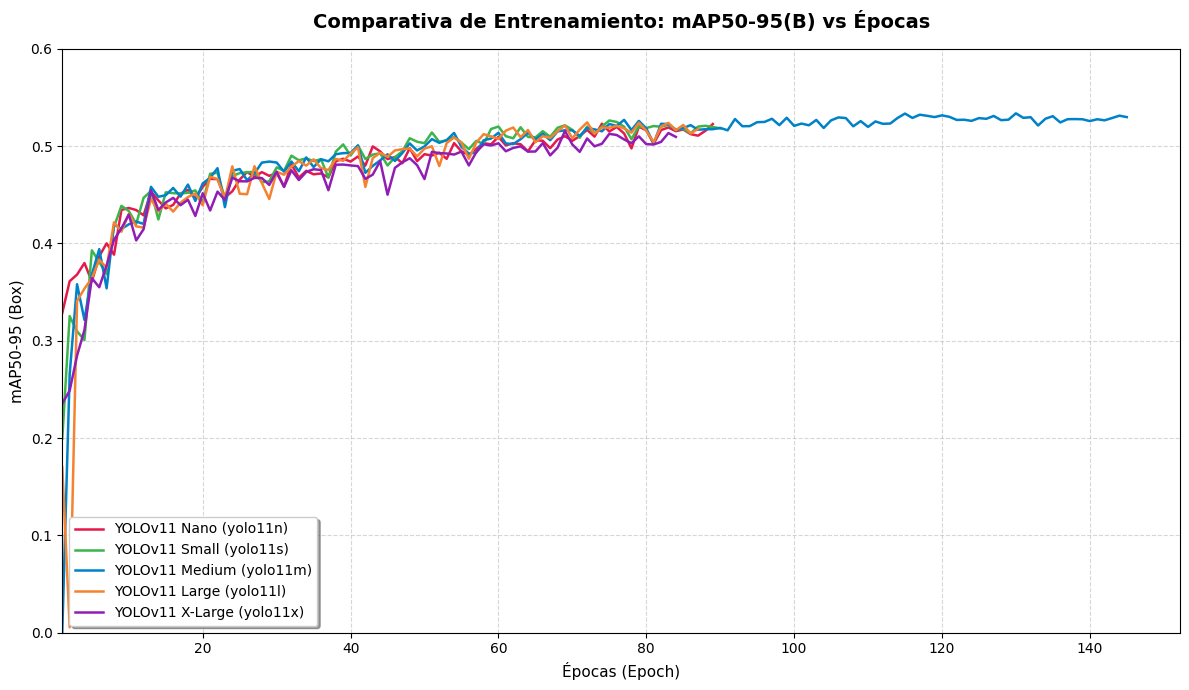

In [49]:
# Comparacion durante el entrenamiento

import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# Forzar remonte seguro de Google Drive para actualizar el caché de archivos
try:
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print(f"[INFO] Nota sobre el montaje de Drive: {e}")

drive_metrics_dir = '/content/drive/MyDrive/CounterStrike_YOLO_Metrics'

# Lista de modelos ordenados de menor a mayor peso
modelos_ordenados = [
    {"id": "yolo11n", "nombre": "YOLOv11 Nano (yolo11n)"},
    {"id": "yolo11s", "nombre": "YOLOv11 Small (yolo11s)"},
    {"id": "yolo11m", "nombre": "YOLOv11 Medium (yolo11m)"},
    {"id": "yolo11l", "nombre": "YOLOv11 Large (yolo11l)"},
    {"id": "yolo11x", "nombre": "YOLOv11 X-Large (yolo11x)"}
]

# Colores muy contrastados para distinguir fácilmente cada modelo con líneas continuas
colores_contraste = [
    '#E6194B',  # Rojo
    '#3CB44B',  # Verde
    '#0082C8',  # Azul
    '#F58231',  # Naranja
    '#911EB4'   # Púrpura
]

plt.figure(figsize=(12, 7))
modelos_graficados = 0

print("Buscando archivos de métricas...")
for i, mod in enumerate(modelos_ordenados):
    csv_name = f"{mod['id']}_training_metrics_backup.csv"

    # Ruta 1: Ruta estándar de Drive
    path_drive = os.path.join(drive_metrics_dir, csv_name)
    # Ruta 2: Búsqueda local en el entorno de Colab
    path_local = os.path.join("runs/detect/runs/cs_v2", csv_name)
    # Ruta 3: Búsqueda local por defecto de Ultralytics (results.csv)
    path_results_local = "runs/detect/runs/cs_v2/results.csv"

    target_path = None
    if os.path.exists(path_drive):
        target_path = path_drive
    elif os.path.exists(path_local):
        target_path = path_local
    elif mod['id'] == 'yolo11l' and os.path.exists(path_results_local):
        target_path = path_results_local

    if target_path:
        print(f" -> Cargando {mod['id']} desde: {target_path}")
        df_mod = pd.read_csv(target_path)
        df_mod.columns = df_mod.columns.str.strip()

        # Graficar con línea continua utilizando el color de alto contraste correspondiente
        plt.plot(
            df_mod["epoch"],
            df_mod["metrics/mAP50-95(B)"],
            label=mod["nombre"],
            color=colores_contraste[i],
            linewidth=1.8
        )
        modelos_graficados += 1
    else:
        # Búsqueda recursiva profunda opcional en Drive si no se encontró en las rutas estándar
        all_found = glob.glob(f"/content/drive/MyDrive/**/{csv_name}", recursive=True)
        if all_found:
            target_path = all_found[0]
            print(f" -> Encontrado mediante búsqueda profunda: {target_path}")
            df_mod = pd.read_csv(target_path)
            df_mod.columns = df_mod.columns.str.strip()

            plt.plot(
                df_mod["epoch"],
                df_mod["metrics/mAP50-95(B)"],
                label=mod["nombre"],
                color=colores_contraste[i],
                linewidth=1.8
            )
            modelos_graficados += 1

if modelos_graficados > 0:
    plt.title("Comparativa de Entrenamiento: mAP50-95(B) vs Épocas", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Épocas (Epoch)", fontsize=11)
    plt.ylabel("mAP50-95 (Box)", fontsize=11)
    plt.ylim(0.0, 0.6)
    plt.xlim(left=1)
    plt.grid(True, linestyle='--', alpha=0.5)
    # Leyenda ubicada abajo a la izquierda (lower left)
    plt.legend(loc="lower left", fontsize=10, frameon=True, shadow=True)
    plt.tight_layout()
    plt.show()
else:
    print("[ALERTA] No se pudo localizar ningún archivo .csv. Asegúrese de que las celdas previas de entrenamiento o respaldo hayan creado los archivos de métricas.")

Buscando archivos de métricas de test (.json) en Google Drive...
 -> Cargando JSON de test para yolo11n...
 -> Cargando JSON de test para yolo11s...
 -> Cargando JSON de test para yolo11m...
 -> Cargando JSON de test para yolo11l...
 -> Cargando JSON de test para yolo11x...

--- TABLA COMPARATIVA EN TEST (mAP50-95) ---


,mAP50-95
Modelo,
YOLOv11 Nano (yolo11n),0.4944
YOLOv11 Small (yolo11s),0.4975
YOLOv11 Medium (yolo11m),0.5142
YOLOv11 Large (yolo11l),0.5074
YOLOv11 X-Large (yolo11x),0.5120


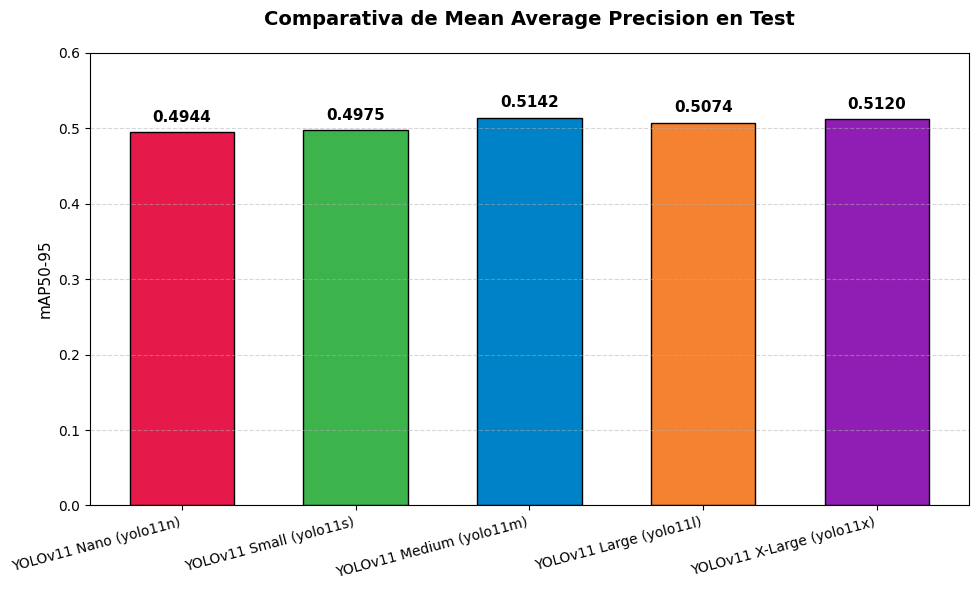

In [50]:
# Comparacion performance en test

import os
import glob
import json
import pandas as pd
import matplotlib.pyplot as plt

drive_metrics_dir = '/content/drive/MyDrive/CounterStrike_YOLO_Metrics'

# Lista de modelos ordenados
modelos_ordenados = [
    {"id": "yolo11n", "nombre": "YOLOv11 Nano (yolo11n)"},
    {"id": "yolo11s", "nombre": "YOLOv11 Small (yolo11s)"},
    {"id": "yolo11m", "nombre": "YOLOv11 Medium (yolo11m)"},
    {"id": "yolo11l", "nombre": "YOLOv11 Large (yolo11l)"},
    {"id": "yolo11x", "nombre": "YOLOv11 X-Large (yolo11x)"}
]

# Colores muy contrastados consistentes con las gráficas anteriores
colores_contraste = [
    '#E6194B',  # Rojo
    '#3CB44B',  # Verde
    '#0082C8',  # Azul
    '#F58231',  # Naranja
    '#911EB4'   # Púrpura
]

datos_test = []

print("Buscando archivos de métricas de test (.json) en Google Drive...")
for mod in modelos_ordenados:
    json_name = f"{mod['id']}_test_metrics_backup.json"
    path_drive = os.path.join(drive_metrics_dir, json_name)

    target_path = None
    if os.path.exists(path_drive):
        target_path = path_drive
    else:
        all_found = glob.glob(f"/content/drive/MyDrive/**/{json_name}", recursive=True)
        if all_found:
            target_path = all_found[0]

    if target_path:
        print(f" -> Cargando JSON de test para {mod['id']}...")
        with open(target_path, 'r') as f:
            metricas = json.load(f)
            datos_test.append({
                "Modelo": mod["nombre"],
                "mAP50-95": metricas.get("mAP50-95", 0.0)
            })

if datos_test:
    # Crear DataFrame de comparación
    df_test_comp = pd.DataFrame(datos_test).set_index("Modelo")

    # Mostrar tabla descriptiva enfocada
    print("\n--- TABLA COMPARATIVA EN TEST (mAP50-95) ---")
    display(df_test_comp.round(4))

    # Crear gráfico de barras individuales exclusivas de mAP50-95
    plt.figure(figsize=(10, 6))
    bars = plt.bar(
        df_test_comp.index,
        df_test_comp["mAP50-95"],
        color=colores_contraste[:len(datos_test)],
        edgecolor='black',
        width=0.6
    )

    plt.title("Comparativa de Mean Average Precision en Test", fontsize=14, fontweight='bold', pad=20)
    plt.ylabel("mAP50-95", fontsize=11)
    plt.ylim(0.0, 0.6)
    plt.xticks(rotation=15, ha='right', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    # Agregar valores encima de cada barra para lectura exacta
    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2.0,
            yval + 0.01,
            f"{yval:.4f}",
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
        )

    plt.tight_layout()
    plt.show()
else:
    print("\n[ALERTA] No se encontraron archivos JSON de métricas de test para ningún modelo en Google Drive.")